# Hong Kong Height Value Transformation

### GPS height transformation within a small local area

This notebook converts a **WGS84 latitude / longitude / ellipsoidal height** into
**HK80 Grid coordinates (Northing / Easting) with an orthometric height above Hong Kong Principal Datum**.

---

## Why a transformation is needed at all

The Geodetic Survey Section of Lands Department states the problem directly:

> In GPS surveys, the surveyed coordinates are computed in the World Geodetic System 1984 (WGS84)
> coordinates which is a geocentric coordinates system, expressed in geodetic coordinates (i.e.
> latitude, longitude and ellipsoidal height) or Cartesian coordinates (i.e. X, Y and Z). In other
> words, the height values obtained from GPS surveys are in **ellipsoidal height referenced to the
> surface of the WGS84 ellipsoid but not the orthometric height above the geoid surface**.
>
> However, the height values we use in daily survey works are in **orthometric height above Hong Kong
> Principal Datum, HKPD**.
>
> — [Geodetic Survey of Hong Kong, *Height Transformation*](https://www.geodetic.gov.hk/en/gi/height_transf.htm)

So there are two different height surfaces in play, and a GNSS receiver only knows about one of them:

| | Reference surface | What it is | Where you meet it |
|---|---|---|---|
| **Ellipsoidal height** `h` | WGS84 ellipsoid | A smooth, geocentric mathematical figure | Raw GPS / GNSS output |
| **Orthometric height** `H` | Hong Kong Principal Datum | A local vertical datum tied to mean sea level, closely following the geoid | Levelling, drawings, daily survey work in Hong Kong |


## How this notebook solves it

The Survey and Mapping Office publishes a set of **control points for the Height Model of Hong Kong**
where *both* heights are known, so `hd` can be measured directly at each one. The method here is the
local-fit idea underlying the SMO procedures, reduced to its simplest form:

1. Find the control points nearest to your survey point.
2. Average their measured `hd`.
3. Apply that average to your GPS height.

For details, please read:

- [Suggested Procedure of Using Leica LGO Software for Transforming GPS Height to Local Height within a Small Local Area](https://www.geodetic.gov.hk/common/data/pdf/GPSHeightTransformationbyLGO.pdf) (PDF)
- [Suggested Procedures of GPS-RTK Survey using Network RTK Data of Hong Kong SatRef System for the Provision of Levels](https://www.geodetic.gov.hk/common/data/pdf/RTKSurveyforProvisionofLevels.pdf) (PDF)
- [Coordinate List of Control Points for Height Model of Hong Kong (Version 1.0)](https://www.geodetic.gov.hk/common/data/pdf/ControlPointsofHKHeightModelv1.0.pdf) (PDF) — **the source of the dataset used below**
- [Distribution Plan of Control Points for Height Model of Hong Kong](https://www.geodetic.gov.hk/common/data/pdf/DistributionPlan.pdf) (PDF) — the official version of the map drawn in section 7


---
## 1. Setup

You need `geopandas` and `pyproj`. If you do not have them yet, installing geopandas from
conda-forge is the least painful route:

```bash
conda install -c conda-forge geopandas pyproj
```

`pandas` and `shapely` come along with geopandas.

In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from pyproj import CRS, Transformer

# Path to the control point file shipped with this repository.
# Adjust if you run the notebook from somewhere other than the repository root.
CONTROL_POINTS_CSV = "data/control_pts_heights.csv"

# How many neighbouring stations to average when correcting a height.
NUM_CLOSEST_STATIONS = 4

print(f"geopandas {gpd.__version__}, pandas {pd.__version__}")

geopandas 0.11.1, pandas 1.4.3


---
## 2. Load the control point data

`data/control_pts_heights.csv` is a space-separated file with **no header row**. Each line is one
control station:

| Column | Meaning |
|---|---|
| `stn` | Station number |
| `lat_d`, `lat_m`, `lat_s` | Latitude in degrees / minutes / seconds |
| `lon_d`, `lon_m`, `lon_s` | Longitude in degrees / minutes / seconds |
| `ell_h` | Ellipsoidal height (metres, above the WGS84 ellipsoid) |
| `pd_h` | Hong Kong Principal Datum height (metres) |

Two things happen on load:

- **DMS → decimal degrees**, because geometry libraries want decimal degrees.
- **Height difference** `hd = pd_h - ell_h` — the local correction at that station.
  This is the number the whole notebook revolves around.

In [2]:
def dms_to_decimal(degrees, minutes, seconds):
    """Convert degrees/minutes/seconds to decimal degrees."""
    return float(degrees) + float(minutes) / 60 + float(seconds) / 3600


def load_stations_csv_as_gdf(csv_path=CONTROL_POINTS_CSV):
    """Read the control point CSV into a GeoDataFrame with lat/lon and height difference."""
    names = ["stn", "lat_d", "lat_m", "lat_s", "lon_d", "lon_m", "lon_s", "ell_h", "pd_h"]
    df = pd.read_csv(csv_path, header=None, sep=" ", names=names)

    df["lat"] = df.apply(lambda r: dms_to_decimal(r["lat_d"], r["lat_m"], r["lat_s"]), axis=1)
    df["lon"] = df.apply(lambda r: dms_to_decimal(r["lon_d"], r["lon_m"], r["lon_s"]), axis=1)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326")

    # The correction we apply later: how far HKPD sits above/below the ellipsoid here.
    gdf["hd"] = gdf["pd_h"] - gdf["ell_h"]
    return gdf


stations_gdf = load_stations_csv_as_gdf()
print(f"Loaded {len(stations_gdf)} control stations")
stations_gdf[["stn", "lat", "lon", "ell_h", "pd_h", "hd"]].head()

Loaded 74 control stations


,stn,lat,lon,ell_h,pd_h,hd
0,141,22.249749,114.174672,11.921,14.460,2.539
1,142,22.256032,114.212460,152.023,154.378,2.355
2,143,22.199068,114.220418,159.095,161.318,2.223
3,146,22.345795,114.215119,268.501,271.065,2.564
4,235,22.280410,114.135346,252.343,255.132,2.789


The height differences are all in the same ballpark but not identical — that spread is exactly why
we interpolate from nearby stations instead of using one global number.

In [3]:
stations_gdf["hd"].describe()

count    74.000000
mean      2.978189
std       0.589577
min       2.080000
25%       2.433000
50%       2.931000
75%       3.523000
max       4.056000
Name: hd, dtype: float64

---
## 3. Find the closest control stations

For an input point we measure the planar distance in **degrees** to every station and keep the
nearest `NUM_CLOSEST_STATIONS`.

> **Why degrees are acceptable here:** measuring distance in degrees is not a true metric distance —
> a degree of longitude is shorter than a degree of latitude. Over an area the size of Hong Kong the
> distortion is small enough that the *ranking* of nearby stations rarely changes. For a larger area
> you would reproject to a metric CRS first.

In [4]:
def point_to_closest_stations_id(stations_gdf, lon, lat, num_of_closest_stations=NUM_CLOSEST_STATIONS):
    """Return [(station_id, distance), ...] for the N stations nearest to (lon, lat)."""
    if num_of_closest_stations <= 0:
        raise ValueError("Number of closest stations must be larger than 0")

    target = Point(lon, lat)
    distances = {row["stn"]: target.distance(row["geometry"]) for _, row in stations_gdf.iterrows()}

    return sorted(distances.items(), key=lambda item: item[1])[:num_of_closest_stations]

Let's try it with a sample point in Hong Kong (this is the one hard-coded in `main.py`):

In [5]:
lat = 22.285663
lon = 114.215286
height = 10.0  # ellipsoidal height, in metres

closest = point_to_closest_stations_id(stations_gdf, lon, lat)

for stn, dist in closest:
    hd = stations_gdf.loc[stations_gdf["stn"] == stn, "hd"].iloc[0]
    print(f"station {stn}: distance {dist:.5f} deg, height difference {hd:+.3f} m")

station HKQB: distance 0.00575 deg, height difference +2.463 m
station QUAR: distance 0.00589 deg, height difference +2.481 m
station 144: distance 0.01864 deg, height difference +2.501 m
station 128: distance 0.02968 deg, height difference +2.363 m


---
## 4. Transform the horizontal position

The horizontal part is a straight coordinate reference system conversion handled by `pyproj`:

- **EPSG:4326** — WGS84 geographic (latitude / longitude in degrees)
- **EPSG:2326** — Hong Kong 1980 Grid (Northing / Easting in metres)

> **Note on axis order:** `EPSG:4326` officially declares its axes as *(latitude, longitude)* and
> `EPSG:2326` as *(Northing, Easting)*. Modern pyproj respects those declarations, so passing
> `(lat, lon)` in returns `(northing, easting)` out — in that order. The original code called these
> `nx, ny`, which reads backwards; they are named explicitly below to avoid confusion.

In [6]:
WGS84 = CRS.from_epsg(4326)   # lat/lon degrees
HK80_GRID = CRS.from_epsg(2326)  # HK 1980 Grid, metres

# Built once and reused — constructing a Transformer is comparatively expensive.
_wgs84_to_hk80 = Transformer.from_crs(WGS84, HK80_GRID)


def transform_wgs84_to_hk80_grid(lat, lon):
    """WGS84 (lat, lon) -> HK80 Grid (northing, easting) in metres."""
    northing, easting = _wgs84_to_hk80.transform(lat, lon)
    return northing, easting


northing, easting = transform_wgs84_to_hk80_grid(lat, lon)
print(f"Northing: {northing:.3f} m")
print(f"Easting:  {easting:.3f} m")

Northing: 816308.645 m
Easting:  840226.480 m


---
## 5. Transform the height

Take the mean `hd` of the nearest stations and apply it:

- **Ellipsoidal → HKPD** (`to_hk80=True`): **add** the mean difference
- **HKPD → ellipsoidal** (`to_hk80=False`): **subtract** it

That is the whole method — a local mean offset. It is simple and works well where stations are dense,
and gets rougher near the edges of the network.

In [7]:
def transform_one_height_value(stations_gdf, lat, lon, height, to_hk80=True):
    """Shift a height by the mean height difference of the nearest control stations."""
    closest = point_to_closest_stations_id(stations_gdf, lon, lat)
    station_ids = [stn for stn, _ in closest]

    mean_hd = stations_gdf.loc[stations_gdf["stn"].isin(station_ids), "hd"].mean()

    return height + mean_hd if to_hk80 else height - mean_hd


new_height = transform_one_height_value(stations_gdf, lat, lon, height)
print(f"Ellipsoidal height : {height:.3f} m")
print(f"HKPD height        : {new_height:.3f} m")

Ellipsoidal height : 10.000 m
HKPD height        : 12.452 m


A quick sanity check — converting back should return the original value:

In [8]:
back = transform_one_height_value(stations_gdf, lat, lon, new_height, to_hk80=False)
print(f"Round trip: {height:.3f} -> {new_height:.3f} -> {back:.3f} m")

Round trip: 10.000 -> 12.452 -> 10.000 m


---
## 6. Put it together

One function that does both the horizontal and the vertical transformation.

In [9]:
def transform_point(stations_gdf, lat, lon, height, to_hk80=True):
    """WGS84 lat/lon/ellipsoidal height -> HK80 Grid northing/easting/HKPD height."""
    northing, easting = transform_wgs84_to_hk80_grid(lat, lon)
    hk_height = transform_one_height_value(stations_gdf, lat, lon, height, to_hk80=to_hk80)
    return northing, easting, hk_height


n, e, h = transform_point(stations_gdf, lat, lon, height)

print(f"Input  (WGS84) : lat {lat}, lon {lon}, ellipsoidal height {height:.3f} m")
print(f"Output (HK80)  : N {n:.3f} m, E {e:.3f} m, HKPD height {h:.3f} m")

Input  (WGS84) : lat 22.285663, lon 114.215286, ellipsoidal height 10.000 m
Output (HK80)  : N 816308.645 m, E 840226.480 m, HKPD height 12.452 m


---
## 7. Visual check (optional)

Plotting the control network with the input point and its chosen neighbours makes it obvious whether
the point sits comfortably inside the network or out on a limb where the result is less reliable.

Requires `matplotlib` (`pip install matplotlib`).

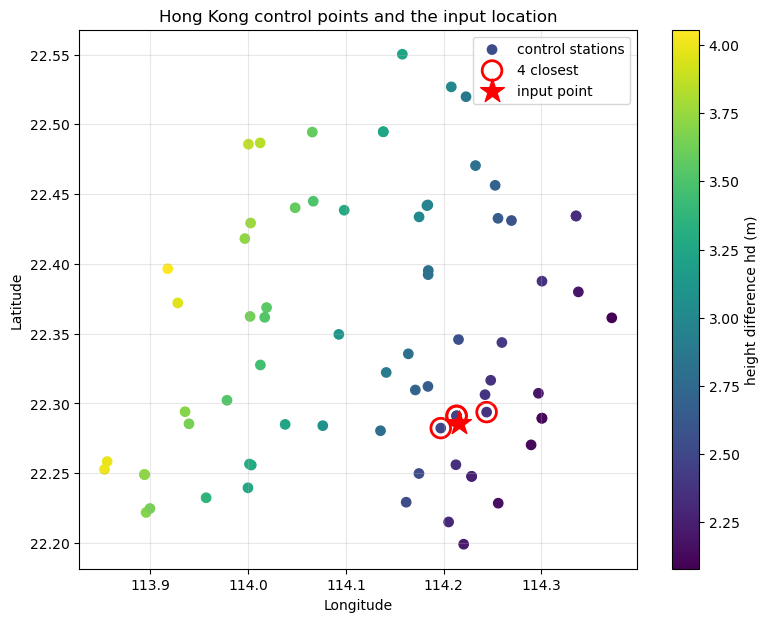

In [10]:
import matplotlib.pyplot as plt

closest_ids = [stn for stn, _ in point_to_closest_stations_id(stations_gdf, lon, lat)]
chosen = stations_gdf[stations_gdf["stn"].isin(closest_ids)]

fig, ax = plt.subplots(figsize=(9, 7))

scatter = ax.scatter(stations_gdf["lon"], stations_gdf["lat"], c=stations_gdf["hd"],
                     cmap="viridis", s=45, label="control stations")
ax.scatter(chosen["lon"], chosen["lat"], facecolors="none", edgecolors="red",
           s=200, linewidths=2, label=f"{len(chosen)} closest")
ax.scatter([lon], [lat], marker="*", c="red", s=320, label="input point", zorder=5)

fig.colorbar(scatter, ax=ax, label="height difference hd (m)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Hong Kong control points and the input location")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

---
## 8. Try your own points

Edit the list below and re-run the cell. Each entry is `(name, latitude, longitude, ellipsoidal height)`.

In [11]:
my_points = [
    ("Sha Tin",          22.382000, 114.188000,  8.0),
]

rows = []
for name, p_lat, p_lon, p_height in my_points:
    p_n, p_e, p_h = transform_point(stations_gdf, p_lat, p_lon, p_height)
    rows.append({
        "name": name,
        "lat": p_lat,
        "lon": p_lon,
        "ellipsoidal_h": p_height,
        "hk80_northing": round(p_n, 3),
        "hk80_easting": round(p_e, 3),
        "hkpd_h": round(p_h, 3),
    })

pd.DataFrame(rows)

,name,lat,lon,ellipsoidal_h,hk80_northing,hk80_easting,hkpd_h
0,Sha Tin,22.382,114.188,8.0,826976.049,837413.754,10.748


---
## Caveats

This is a test implementation, please reference the authoritative transformations documentation and tools published on [Suggested Procedures for GPS Height Transformation within a Small Local Area](https://www.geodetic.gov.hk/en/gi/height_transf.htm)

- **Unweighted mean.** All four neighbours count equally, however far away they are. Inverse-distance
  weighting would be a natural improvement.
- **No extrapolation guard.** A point far outside the control network still returns a number, and that
  number should not be trusted. Section 7 is the visual version of this warning.
